# 作业1 线性回归作业
0927
- 使用 Python + NumPy，不直接调用 sklearn 线性回归模型，编程实现线性回归（解析解 + 梯度下降）；
- 数据集：网上数据集或者自己构造带噪声的合成数据集。
- 训练过程：
    - 绘制损失、模型参数随迭代次数的变化曲线；调学习率观察收敛变化；
    - 可视化：训练散点 + 拟合直线或平面（单变量、2变量时）

# 数据集

In [1]:
# 加载清洗数据集
import sys, pathlib
sys.path.append(str(pathlib.Path.cwd().parent))

from my_datasets.diabetes_utils import load_diabetes_ready
x_train, x_test, y_train, y_test, scaler = load_diabetes_ready()  # 数据集处理单独封装，达到复用目的

display(x_train)
display(y_train)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
400,-0.517200,-0.931518,0.958061,1.936805,-0.372416,-0.735060,1.605548,-0.837408,-0.727075,-0.220574
409,-1.126026,1.073517,-0.252390,1.199326,1.209708,1.569708,-0.894306,1.551319,0.627438,-0.132593
266,-1.126026,1.073517,-1.325810,0.240604,-0.167326,-0.761705,2.772146,-1.633650,-1.815618,0.043367
193,0.167729,1.073517,-0.115358,-1.381849,1.502694,1.802849,-0.894306,1.551319,0.814300,0.395288
130,-1.354335,1.073517,2.031481,2.231797,-0.050131,-0.082265,-0.144349,-0.041166,0.463531,1.539030
...,...,...,...,...,...,...,...,...,...,...
358,-0.441097,-0.931518,-1.805423,-0.570623,-0.753298,-0.708416,0.938920,-1.100168,-1.723040,-1.012395
356,-0.136684,1.073517,-0.709165,-0.349379,0.184257,0.364034,0.355621,-0.041166,-0.598074,-1.628256
300,0.319935,-0.931518,1.551868,-0.889951,-0.079430,-0.268778,-0.311006,-0.009316,0.884113,0.923169
132,0.319935,1.073517,-0.457939,-0.201883,0.740931,1.036814,0.022307,-0.041166,-0.277278,0.483268


400    175.0
409    181.0
266     45.0
193    116.0
130    274.0
       ...  
358     90.0
356     54.0
300    275.0
132    107.0
373    168.0
Name: target, Length: 353, dtype: float64

# 单变量

## 解析解法
<!-- ![image.png](./第二章%20线性模型_pages/单变量-解析解法/page_014.png) -->
<img src="./第二章%20线性模型_pages/单变量-解析解法/page_014.png" width="50%">

重点：编程实现3.7和38公式

In [2]:
# 单变量线性回归 —— 解析解（严格按课件《第二章 线性模型》单变量-解析解法推导实现）
# 损失函数  E(w,b) = 1/(2m) * Σ (y_i - w*x_i - b)^2                （课件 page 7）
# 公式(3.7) w = Σ y_i*(x_i - x̄) / [Σ x_i² - (1/m)*(Σ x_i)²]        （课件 page 14）
# 公式(3.8) b = (1/m) * Σ (y_i - w*x_i)                            （课件 page 14）
# 计算顺序：先由 (3.7) 求 w，再代回 (3.8) 求 b
import numpy as np

# ---------- 1 准备单变量数据 ----------
# 单变量：只用一个特征 x = bmi（体重指数，已标准化；与 target 相关性最强 r≈0.58）
# 目标值 y 用 y_train：diabetes 的 target 本身就是连续的疾病进展评分，无需做类别映射
x = x_train['bmi'].to_numpy()                   # 形状 (m,)
y = y_train.to_numpy()                          # 形状 (m,)，连续值 → 回归任务
m = len(x)                                      # 训练样本数

# ---------- 2 公式(3.7) 求 w ----------
x_bar = x.sum() / m                             # x̄：x 的均值
w = (y * (x - x_bar)).sum() / (np.sum(x**2) - x.sum()**2 / m)

# ---------- 3 公式(3.8) 求 b ----------
b = (y - w * x).sum() / m

# ---------- 4 用损失函数 E(w,b) 验证拟合效果 ----------
E = np.sum((w * x + b - y) ** 2) / (2 * m)

print(f'样本数 m       = {m}')
print(f'x 均值 x̄      = {x_bar:.6f}')
print(f'解析解 w (3.7) = {w:.6f}')
print(f'解析解 b (3.8) = {b:.6f}')
print(f'损失 E(w,b)    = {E:.6f}')


样本数 m       = 353
x 均值 x̄      = 0.000000
解析解 w (3.7) = 44.234093
解析解 b (3.8) = 152.022663
损失 E(w,b)    = 1961.272833


## 梯度下降法
<!-- ![image.png](./第二章%20线性模型_pages/单变量-梯度下降法/page_020.png) -->
<img src="./第二章%20线性模型_pages/单变量-梯度下降法/page_020.png" width="50%">

重点：编程实现两个偏导数表达式，并定义循环和停止阈值，实现梯度下降逻辑

In [3]:
# 单变量线性回归 —— 梯度下降法（严格按课件《单变量-梯度下降法》p18-21 实现）
# 更新规则（批量梯度下降：每一步用所有训练样本，w、b 必须同步更新）：
#   b := b − α·Σ(f(x_i) − y_i)
#   w := w − α·Σ(f(x_i) − y_i)·x_i
# 本节损失函数（课件 p19，注意系数是 1/2 而非 1/2m）：E(w,b) = (1/2)·Σ(f(x_i) − y_i)²
import numpy as np

# ==================== 超参数与停止阈值（集中定义，便于统一调整） ====================
LEARNING_RATE = 0.003    # 学习率 α（稳定上界 2/Σx² ≈ 2/353 ≈ 0.0057，过大会发散）
MAX_ITERS     = 5000     # 最大迭代次数（课件 p32 示例即 5000 次）
TOL           = 1e-10    # 停止阈值：相邻两次损失变化 < TOL 即认为已收敛
W_INIT        = 0.0      # 起始点 w（课件思想：从某个起始点开始下降）
B_INIT        = 0.0      # 起始点 b


# ==================== 梯度下降主体 ====================
def gradient_descent(x, y, lr=LEARNING_RATE, max_iter=MAX_ITERS, tol=TOL,
                     w=W_INIT, b=B_INIT):
    """批量梯度下降求解单变量线性回归。

    返回: (w, b, history)
        history: (iters+1, 3) 数组，每行是 [损失E, w, b]，
                 含第 0 次迭代前的初始状态，供后续绘制损失/参数变化曲线。
    """
    history = [(np.sum((w * x + b - y) ** 2) / 2, w, b)]   # 记录初始状态
    for t in range(max_iter):
        f = w * x + b                          # 当前模型预测 f(x_i)
        grad_w = np.sum((f - y) * x)           # ∂E/∂w（课件 p20）
        grad_b = np.sum(f - y)                 # ∂E/∂b（课件 p20）
        w, b = w - lr * grad_w, b - lr * grad_b   # 同步更新（课件 p18）
        history.append((np.sum((w * x + b - y) ** 2) / 2, w, b))
        if abs(history[-2][0] - history[-1][0]) < tol:    # 损失几乎不再下降 → 停止
            break
    return w, b, np.array(history)


# ==================== 运行（沿用解析解单元格的 x、y） ====================
w_gd, b_gd, gd_history = gradient_descent(x, y)

print(f'迭代次数   = {len(gd_history) - 1}')
print(f'梯度下降 w = {w_gd:.6f}')
print(f'梯度下降 b = {b_gd:.6f}')
print(f'最终损失 E = {gd_history[-1, 0]:.6f}')
print(f'(对照解析解: w = {w:.6f}, b = {b:.6f}, E(1/2·Σ) = {E * 2 * m:.6f})')


迭代次数   = 8
梯度下降 w = 44.234093
梯度下降 b = 152.022663
最终损失 E = 692329.309921
(对照解析解: w = 44.234093, b = 152.022663, E(1/2·Σ) = 1384658.619841)


### 绘制损失、模型参数随迭代次数的变化曲线

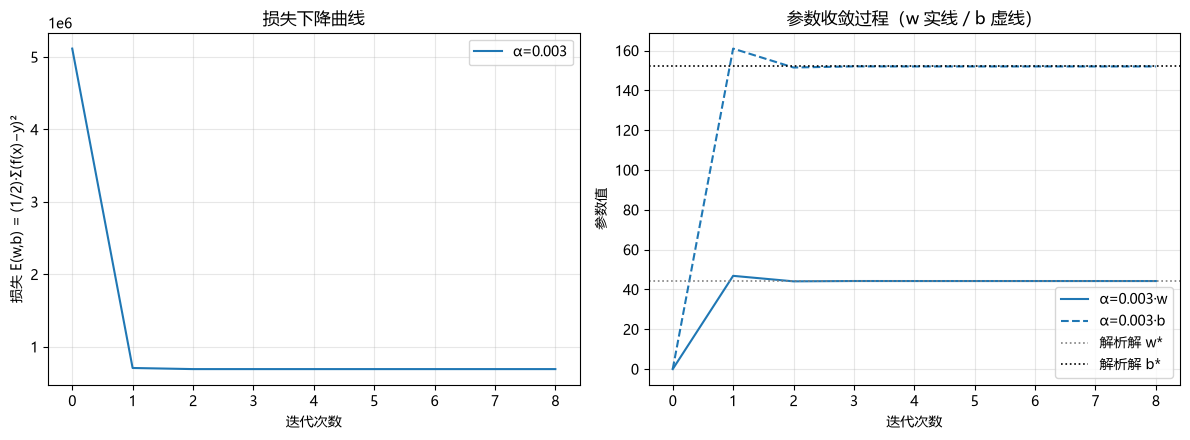

In [4]:
# 绘制损失、模型参数随迭代次数的变化曲线（封装成函数，支持对比多组训练结果）
import matplotlib.pyplot as plt

# 中文显示设置（Windows 优先，兼容 macOS）
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Arial Unicode MS', 'PingFang SC', 'Hiragino Sans GB']  # 把 Windows 中文字体放到最前面，原 macOS 字体保留兜底
plt.rcParams['axes.unicode_minus'] = False  # 保持不变


def plot_gd_curves(histories, labels, w_star=None, b_star=None):
    """绘制梯度下降训练的损失曲线与参数收敛曲线。

    参数:
        histories: list，一个或多个训练记录（gradient_descent 返回的 history，
                   形状 (iters+1, 3)，每行 [损失E, w, b]，含第 0 点初始状态）
        labels:    list，与 histories 一一对应的标签（说明对应的超参数组）
        w_star / b_star: 可选，解析解 w、b，用于画对照虚线
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
    colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']

    for h, lab, c in zip(histories, labels, colors):
        iters = np.arange(len(h))
        # 左图：损失 E 随迭代次数的变化（对应课件 p32 下图）
        ax1.plot(iters, h[:, 0], color=c, label=lab)
        # 右图：参数收敛过程（w 实线、b 虚线，同色 = 同一组训练）
        ax2.plot(iters, h[:, 1], color=c, ls='-', label=f'{lab}·w')
        ax2.plot(iters, h[:, 2], color=c, ls='--', label=f'{lab}·b')

    if w_star is not None:
        ax2.axhline(w_star, color='gray', ls=':', lw=1.2, label='解析解 w*')
    if b_star is not None:
        ax2.axhline(b_star, color='black', ls=':', lw=1.2, label='解析解 b*')

    ax1.set_xlabel('迭代次数')
    ax1.set_ylabel('损失 E(w,b) = (1/2)·Σ(f(x)−y)²')
    ax1.set_title('损失下降曲线')
    ax1.legend()
    ax1.grid(alpha=0.3)

    ax2.set_xlabel('迭代次数')
    ax2.set_ylabel('参数值')
    ax2.set_title('参数收敛过程（w 实线 / b 虚线）')
    ax2.legend()
    ax2.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


# 调用：当前这组训练结果（之后调学习率时，把多组 history 一起传入即可对比）
plot_gd_curves([gd_history],
               [f'α={LEARNING_RATE}'],
               w_star=w, b_star=b)  # 解析解 w、b 直接引用解析解单元格的变量

### 调学习率观察收敛变化；

α=0.0005 迭代   96 次 → w=44.234092, b=152.022662, E=692329.309921


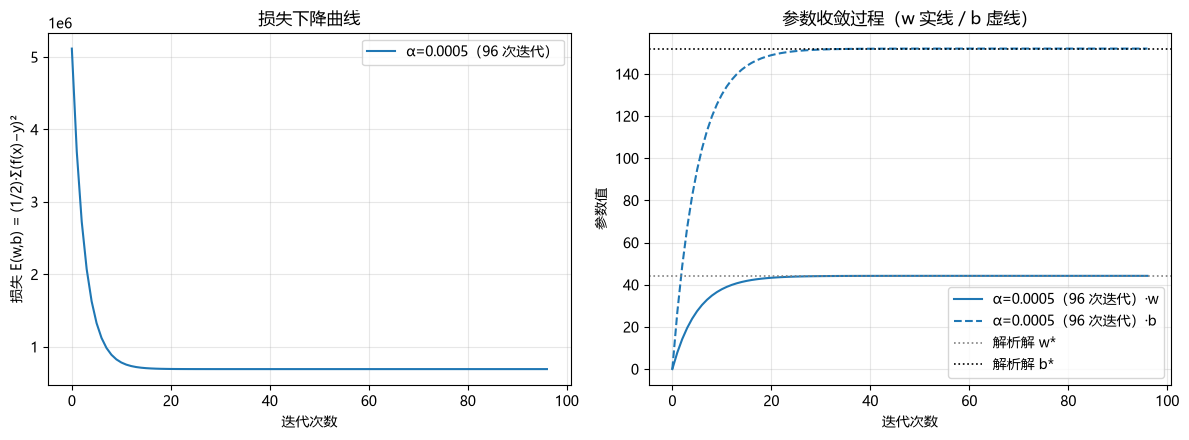

α=0.003  迭代    8 次 → w=44.234093, b=152.022663, E=692329.309921


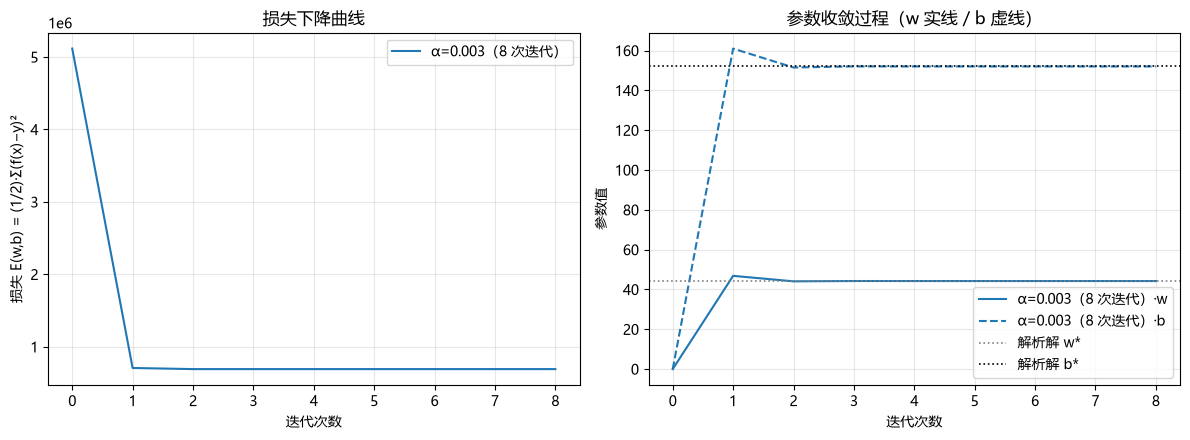

α=0.0055 迭代  299 次 → w=44.234093, b=152.022665, E=692329.309921


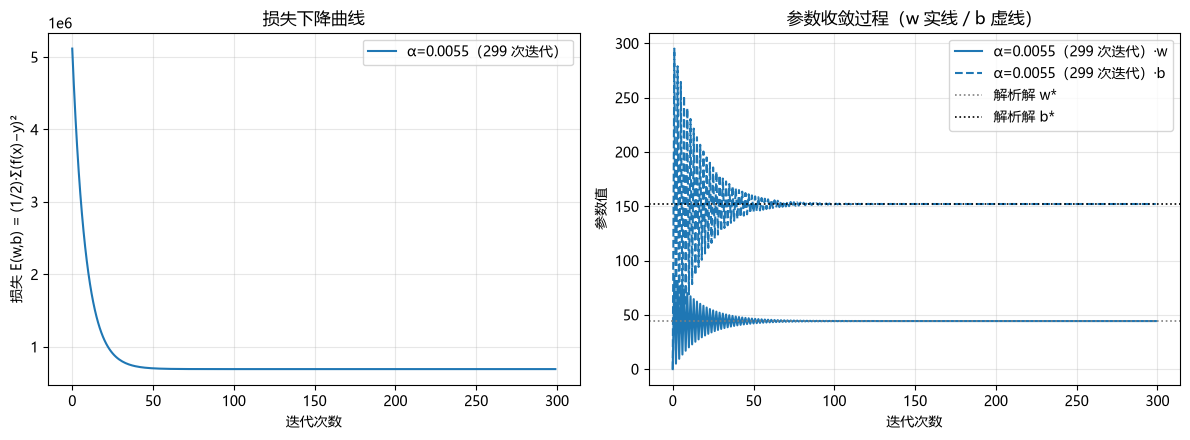

In [5]:
# 调学习率观察收敛变化：对比 3 组不同学习率 α 的训练过程
# 训练直接复用上一单元格的 gradient_descent，绘图直接复用 plot_gd_curves

# 三组学习率的设计（本任务稳定上界 = 2/Σx² ≈ 2/353 ≈ 0.0057）：
#   α=0.0005 偏小 → 每步挪得少，收敛慢、曲线平滑
#   α=0.003  适中 → 快速平稳收敛
#   α=0.0055 偏大 → 逼近稳定上界，参数来回震荡后收敛（超过 0.0057 则发散，可自行验证）
learning_rates = [0.0005, 0.003, 0.0055]

histories, labels = [], []
for i, lr in enumerate(learning_rates):
    w_lr, b_lr, h = gradient_descent(x, y, lr=lr)
    histories.append(h)
    labels.append(f'α={lr}（{len(h) - 1} 次迭代）')
    print(f'α={lr:<6} 迭代 {len(h) - 1:4d} 次 → w={w_lr:.6f}, b={b_lr:.6f}, E={h[-1, 0]:.6f}')

    # 三组损失曲线 / 参数收敛曲线同图对比，虚线为解析解
    plot_gd_curves([histories[i]], [labels[i]], w_star=w, b_star=b)


### 可视化：训练散点 + 拟合直线

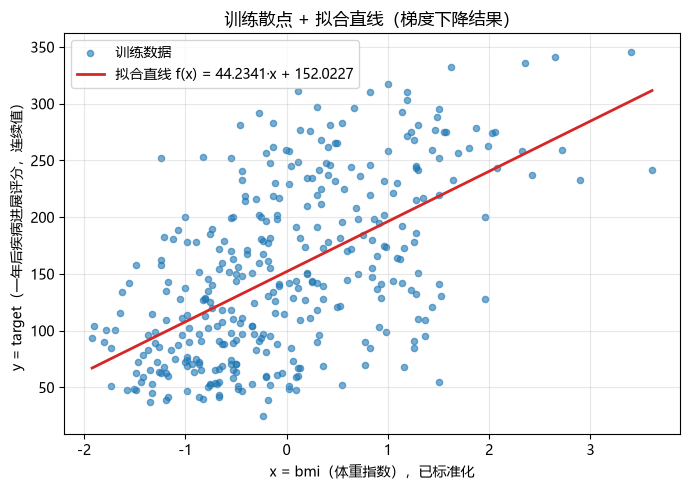

In [6]:
# 可视化：训练散点 + 拟合直线
# 使用最初始超参数（α=LEARNING_RATE=0.003）训练的 gd_history 的最终参数 w_gd, b_gd
# 对应课件《单变量-梯度下降法》p32 上图：预测函数（红线）+ 训练数据（散点）
import matplotlib.pyplot as plt

# 中文显示设置（Windows 优先，兼容 macOS）
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Arial Unicode MS', 'PingFang SC', 'Hiragino Sans GB']  # 把 Windows 中文字体放到最前面，原 macOS 字体保留兜底
plt.rcParams['axes.unicode_minus'] = False  # 保持不变


def plot_fit_line(x, y, w, b):
    """绘制单变量线性回归的训练散点 + 拟合直线 f(x) = w·x + b。

    参数:
        x, y: 训练数据（形状 (m,)）
        w, b: 模型参数（梯度下降结果 w_gd, b_gd）
    """
    fig, ax = plt.subplots(figsize=(7, 5))

    ax.scatter(x, y, s=20, alpha=0.6, color='tab:blue', label='训练数据')
    x_line = np.linspace(x.min(), x.max(), 100)        # 在 x 取值范围内取点画直线
    ax.plot(x_line, w * x_line + b, color='tab:red', lw=2,
            label=f'拟合直线 f(x) = {w:.4f}·x + {b:.4f}')

    ax.set_xlabel('x = bmi（体重指数），已标准化')
    ax.set_ylabel('y = target（一年后疾病进展评分，连续值）')
    ax.set_title('训练散点 + 拟合直线（梯度下降结果）')
    ax.legend()
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


# 调用：最初始超参数训练得到的参数
plot_fit_line(x, y, w_gd, b_gd)

# 2变量

## 解析解法

<img src="./第二章%20线性模型_pages/多变量-解析解法/page_039.png" width="50%">

重点：编程实现矩阵形式，实现上述ppt最后一行表达式

In [8]:
# 2变量线性回归 —— 解析解（严格按课件《多变量-解析解法》p33-39 以向量形式实现）
# 模型: y = w0·1 + w1·x1 + w2·x2 = w^T·x      （课件 p33：令 w0=b, x0=1）
# 损失: E(w) = (1/2)·||Xw − y||²               （课件 p37 矩阵形式）
# 正规方程: w = (X^T·X)^(-1)·X^T·y = X⁺·y      （课件 p39，凸函数梯度为零处）
import numpy as np

# ---------- 1 准备 2 变量数据（与单变量一节保持一致的目标值） ----------
# 两个特征: x1 = bmi（体重指数）, x2 = s5（log 血清甘油三酯）（均已标准化，与 target 相关性最强的两个特征）
# 目标值:   y = 疾病进展评分（连续值，直接用 y_train，无需类别映射）
E_1v = E                                            # 保存单变量解析解的损失 E(1/2m·Σ)，供下方对照打印
y = y_train.to_numpy()                              # 形状 (m,)，连续值
m = len(y)                                          # 训练样本数
X0 = x_train[['bmi', 's5']].to_numpy()              # (m, 2)

# ---------- 2 构造设计矩阵 X：每行一个样本，首列补 1（课件 p36） ----------
X = np.hstack([np.ones((m, 1)), X0])                # (m, 3)

# ---------- 3 正规方程求解析解 w = (X^T·X)^(-1)·X^T·y ----------
w_vec = np.linalg.inv(X.T @ X) @ X.T @ y            # (3,) = [b, w1, w2]

# ---------- 4 拆分参数并计算损失 ----------
b2, w1, w2 = w_vec[0], w_vec[1], w_vec[2]           # w[0] 即偏置 b
E = np.sum((X @ w_vec - y) ** 2) / 2                # E = (1/2)·||Xw − y||²

print(f'样本数 m        = {m}')
print(f'解析解 b (w0)   = {b2:.6f}')
print(f'解析解 w1 (bmi) = {w1:.6f}')
print(f'解析解 w2 (s5)  = {w2:.6f}')
print(f'损失 E(1/2·Σ)   = {E:.6f}')
print(f'损失 E(1/2m·Σ)  = {E / (2 * m):.6f}  (单变量解析解为 {E_1v:.6f}，加入 w2 后更小)')
print(f'(对照 np.linalg.lstsq: {np.allclose(w_vec, np.linalg.lstsq(X, y, rcond=None)[0])})')


样本数 m        = 353
解析解 b (w0)   = 152.022663
解析解 w1 (bmi) = 30.146924
解析解 w2 (s5)  = 31.020733
损失 E(1/2·Σ)   = 557511.988457
损失 E(1/2m·Σ)  = 789.677037  (单变量解析解为 557511.988457，加入 w2 后更小)
(对照 np.linalg.lstsq: True)


## 梯度下降法

### 绘制损失、模型参数随迭代次数的变化曲线

<img src="./第二章%20线性模型_pages/多变量-梯度下降法/page_040.png" width="50%">

重点：矩阵形式实现上面梯度下降法

迭代次数      = 33
梯度下降 w    = [152.022663  30.146924  31.020733]   （w0 即偏置 b）
最终损失 E    = 557511.988457
(对照解析解   = [152.022663  30.146924  31.020733])


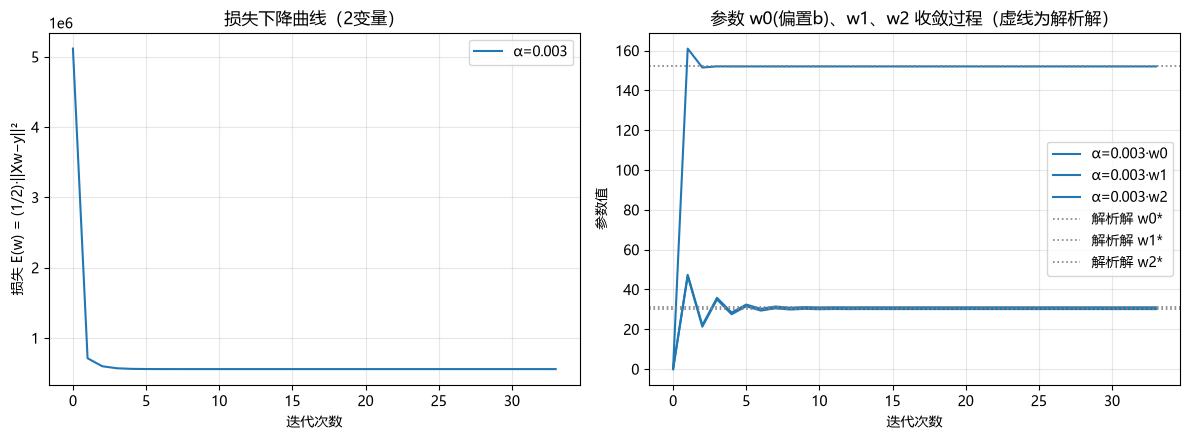

In [9]:
# 2变量线性回归 —— 梯度下降法（严格按课件《多变量-梯度下降法》p40，向量形式实现）
# 更新规则（批量梯度下降，与解析解共用上面的设计矩阵 X、目标值 y）：
#   w := w − α·X^T·(Xw − y)        —— 课件 p40 的 w_j := w_j − α·Σ(f(x_i)−y_i)·x_ij 的向量形式，
#                                       整个参数向量一次赋值，天然满足"同时更新 w_j, j=0,1,…,n"
# 损失函数（课件 p40，系数 1/2）：E(w) = (1/2)·||Xw − y||²
import numpy as np
import matplotlib.pyplot as plt

# ==================== 超参数与停止阈值（集中定义，便于统一调整） ====================
LEARNING_RATE_2V = 0.003   # 学习率 α（稳定上界 2/λmax(XᵀX) ≈ 2/513 ≈ 0.0039，过大会发散）
MAX_ITERS_2V     = 5000    # 最大迭代次数
TOL_2V           = 1e-10   # 停止阈值：相邻两次损失变化 < TOL 即认为已收敛
W_INIT_2V        = None    # 起始点 w 向量（None = 零向量 [0, 0, 0]）


# ==================== 梯度下降主体（向量形式） ====================
def gradient_descent_vec(X, y, lr=LEARNING_RATE_2V, max_iter=MAX_ITERS_2V, tol=TOL_2V,
                         w=None):
    """向量形式批量梯度下降求解多变量线性回归。

    返回: (w, history)
        history: (iters+1, n+2) 数组，每行是 [损失E, w0, w1, w2]，
                 含第 0 次迭代前的初始状态，供绘制损失/参数变化曲线。
    """
    w = np.zeros(X.shape[1]) if w is None else w.copy()
    history = [(np.sum((X @ w - y) ** 2) / 2, *w)]        # 记录初始状态
    for t in range(max_iter):
        w = w - lr * (X.T @ (X @ w - y))                  # 同步更新（一次向量运算）
        history.append((np.sum((X @ w - y) ** 2) / 2, *w))
        if abs(history[-2][0] - history[-1][0]) < tol:    # 损失几乎不再下降 → 停止
            break
    return w, np.array(history)


def plot_gd_curves_n(histories, labels, w_star=None):
    """绘制多变量梯度下降的损失曲线与各参数收敛曲线（plot_gd_curves 的多变量推广版）。

    参数:
        histories: list，训练记录（gradient_descent_vec 返回的 history，
                   每行 [损失E, w0, w1, …, wn]）
        labels:    list，与 histories 一一对应的标签
        w_star:    可选，解析解参数向量，用于画对照虚线
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
    colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']

    for h, lab, c in zip(histories, labels, colors):
        iters = np.arange(len(h))
        ax1.plot(iters, h[:, 0], color=c, label=lab)
        for j in range(h.shape[1] - 1):                   # 逐个参数画收敛曲线
            ax2.plot(iters, h[:, j + 1], color=c, label=f'{lab}·w{j}')

    if w_star is not None:                                # 解析解对照（虚线）
        for j, ws in enumerate(np.atleast_1d(w_star)):
            ax2.axhline(ws, color='gray', ls=':', lw=1.2, label=f'解析解 w{j}*')

    ax1.set_xlabel('迭代次数')
    ax1.set_ylabel('损失 E(w) = (1/2)·||Xw−y||²')
    ax1.set_title('损失下降曲线（2变量）')
    ax1.legend()
    ax1.grid(alpha=0.3)

    ax2.set_xlabel('迭代次数')
    ax2.set_ylabel('参数值')
    ax2.set_title('参数 w0(偏置b)、w1、w2 收敛过程（虚线为解析解）')
    ax2.legend()
    ax2.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


# ==================== 运行（沿用解析解单元格的 X、y，结果直接对应） ====================
w_gd_vec, gd_hist_vec = gradient_descent_vec(X, y)

print(f'迭代次数      = {len(gd_hist_vec) - 1}')
print(f'梯度下降 w    = {w_gd_vec.round(6)}   （w0 即偏置 b）')
print(f'最终损失 E    = {gd_hist_vec[-1, 0]:.6f}')
print(f'(对照解析解   = {w_vec.round(6)})')

plot_gd_curves_n([gd_hist_vec], [f'α={LEARNING_RATE_2V}'], w_star=w_vec)

### 调学习率观察收敛变化；

=== α = 0.001 ===
迭代次数   = 62
梯度下降 w = [152.022663  30.146924  31.020732]
最终损失 E = 557511.988457
(对照解析解 = [152.022663  30.146924  31.020733])



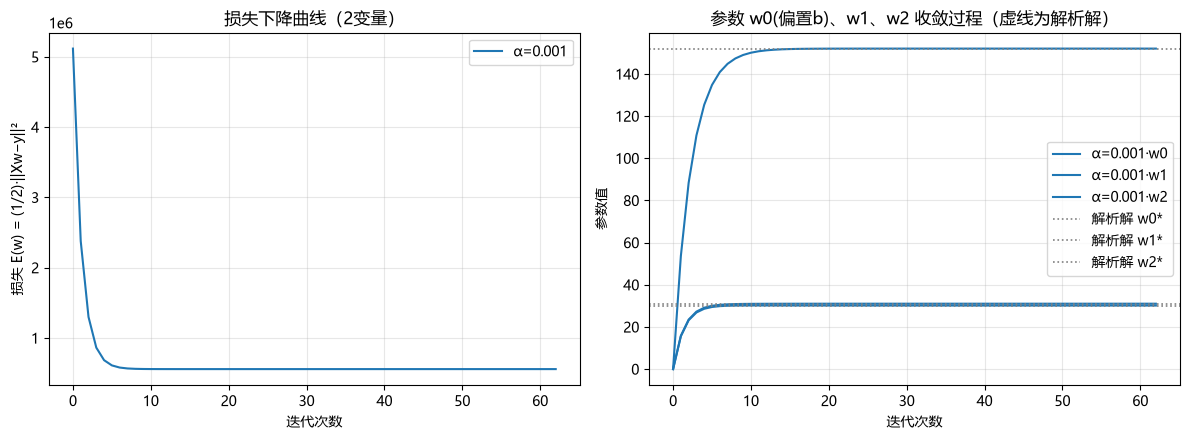

=== α = 0.003 ===
迭代次数   = 33
梯度下降 w = [152.022663  30.146924  31.020733]
最终损失 E = 557511.988457
(对照解析解 = [152.022663  30.146924  31.020733])



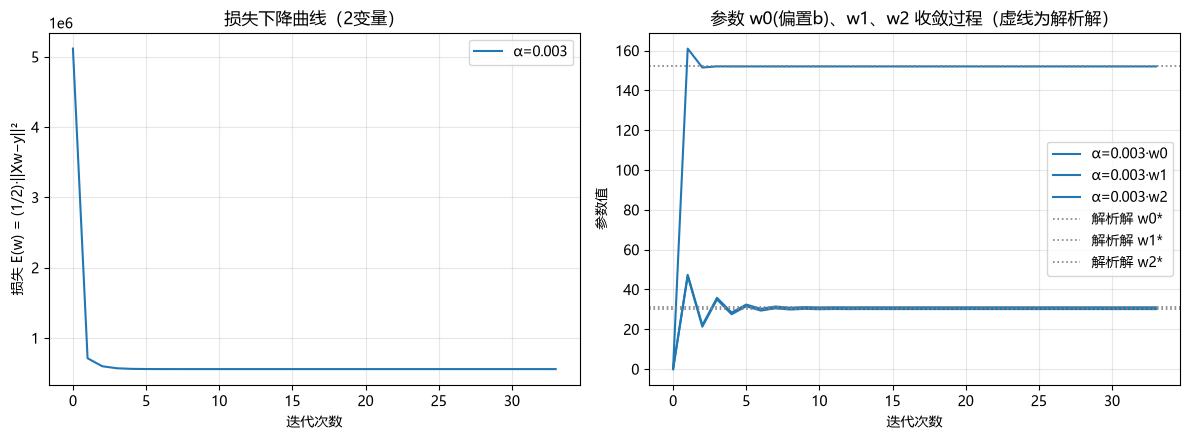

=== α = 0.0038 ===
迭代次数   = 328
梯度下降 w = [152.022663  30.146922  31.020731]
最终损失 E = 557511.988457
(对照解析解 = [152.022663  30.146924  31.020733])



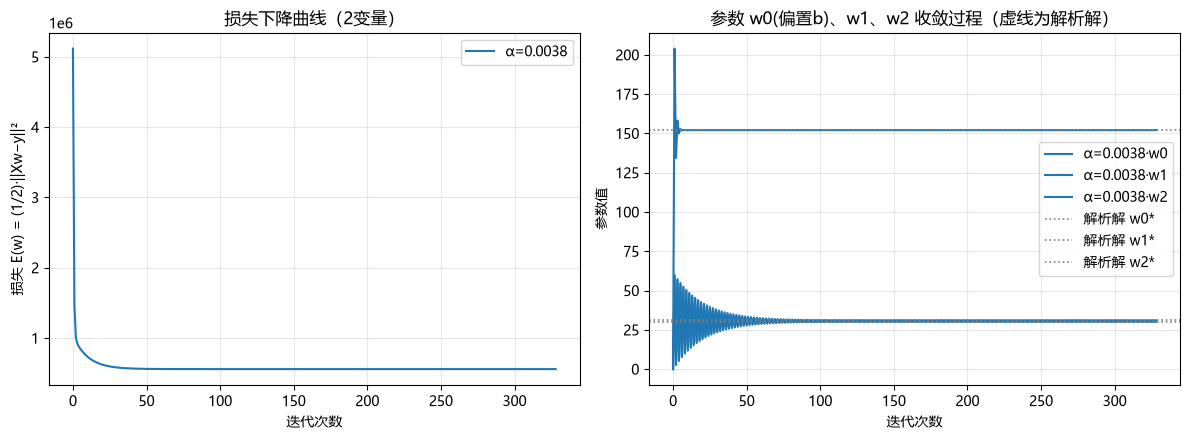

In [10]:
# 调学习率观察收敛变化（2变量）：对比 3 组不同学习率 α，分三次训练并分别输出
# 训练复用上一单元格的 gradient_descent_vec，绘图复用 plot_gd_curves_n（参考单变量的方式）
#
# 三组学习率的设计（本任务稳定上界 2/λmax(XᵀX) ≈ 2/513 ≈ 0.0039）：
#   α=0.001  偏小 → 每步挪得少，收敛慢、曲线平滑
#   α=0.003  适中 → 平稳收敛（默认值）
#   α=0.0038 偏大 → 接近稳定上界，参数来回震荡后收敛（超过 0.0039 则发散，可自行验证）
learning_rates_2v = [0.001, 0.003, 0.0038]

for lr in learning_rates_2v:
    # ---- 训练一组学习率 ----
    w_lr, h_lr = gradient_descent_vec(X, y, lr=lr)

    # ---- 打印该组结果 ----
    print(f'=== α = {lr} ===')
    print(f'迭代次数   = {len(h_lr) - 1}')
    print(f'梯度下降 w = {w_lr.round(6)}')
    print(f'最终损失 E = {h_lr[-1, 0]:.6f}')
    print(f'(对照解析解 = {w_vec.round(6)})\n')

    # ---- 单独绘制该组的损失/参数收敛曲线（分三次输出） ----
    plot_gd_curves_n([h_lr], [f'α={lr}'], w_star=w_vec)


### 可视化：训练散点 + 拟合平面

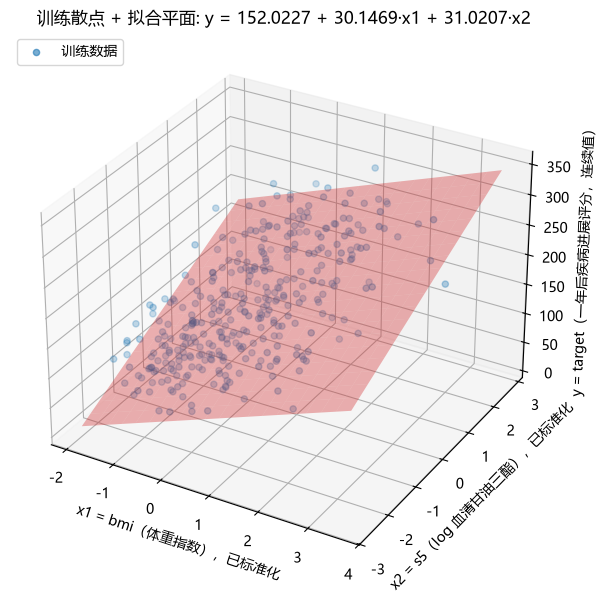

In [11]:
# 可视化：训练散点 + 拟合平面（2变量线性回归，三维图）
# 使用默认超参数（α=LEARNING_RATE_2V=0.003）训练的 w_gd_vec，与解析解几乎一致
# 拟合平面: y = w0 + w1·x1 + w2·x2
import matplotlib.pyplot as plt

# 中文显示设置（Windows 优先，兼容 macOS）
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Arial Unicode MS', 'PingFang SC', 'Hiragino Sans GB']  # 把 Windows 中文字体放到最前面，原 macOS 字体保留兜底
plt.rcParams['axes.unicode_minus'] = False  # 保持不变


def plot_fit_plane(X0, y, w):
    """绘制 2 变量线性回归的训练散点 + 拟合平面（3D 图）。

    参数:
        X0: (m, 2) 两个特征的原始数据（不含 1 列）
        y:  (m,)   目标值
        w:  (3,)   模型参数 [w0(偏置b), w1, w2]（梯度下降结果 w_gd_vec）
    """
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(projection='3d')

    # 训练散点
    ax.scatter(X0[:, 0], X0[:, 1], y, s=20, alpha=0.6,
               color='tab:blue', label='训练数据')

    # 拟合平面：在两特征的取值范围内铺网格，按模型计算 z
    g1 = np.linspace(X0[:, 0].min(), X0[:, 0].max(), 20)
    g2 = np.linspace(X0[:, 1].min(), X0[:, 1].max(), 20)
    G1, G2 = np.meshgrid(g1, g2)
    ax.plot_surface(G1, G2, w[0] + w[1] * G1 + w[2] * G2,
                    alpha=0.35, color='tab:red')

    ax.set_xlabel('x1 = bmi（体重指数），已标准化')
    ax.set_ylabel('x2 = s5（log 血清甘油三酯），已标准化')
    ax.set_zlabel('y = target（一年后疾病进展评分，连续值）')
    ax.set_title(f'训练散点 + 拟合平面: y = {w[0]:.4f} + {w[1]:.4f}·x1 + {w[2]:.4f}·x2')
    ax.legend(loc='upper left')

    plt.tight_layout()
    plt.show()


# 调用：默认超参数训练得到的参数
plot_fit_plane(X0, y, w_gd_vec)